# Do balance patches explain win rate changes in Overwatch 2?

## What is Overwatch?
Overwatch is a team-based hero shooter developed by Blizzard Entertainment and first released in 2016. Its sequel, Overwatch 2, launched in October 2022 as a free-to-play game and switched from 6v6 to 5v5 matches. Before each match, players choose a hero from a roster divided into three roles: Tank, Damage and Support. Every hero has its own weapon and abilities (cooldowns, ultimate, etc.), so keeping them balanced is a constant concern for the developers.

The game is played in seasons of about two months. In competitive mode, players are placed in rank tiers, from Bronze to Grandmaster. The developers regularly publish patch notes listing the changes made to each hero: a **buff** makes a hero stronger (more damage, shorter cooldown...) and a **nerf** makes it weaker. Two statistics are commonly used to follow how a hero is doing: the **win rate** (the share of matches won with that hero) and the **pick rate** (how often the hero is played).

## About this project
The goal of this project is to check whether the balance changes made by the developers can be linked to the evolution of hero win rates between two seasons. It combines two sources:

1. **A Kaggle dataset** with the statistics of every hero in competitive mode (win rate, pick rate, KDA ratio) for each rank tier and each season. We use seasons 1 and 2 of Overwatch 2.
The Kaggle dataset was made by Mykhailo Kachan. From his words, this dataset is built on data from Overbuff with the help of python and selenium.
Link: https://www.kaggle.com/datasets/mykhailokachan/overwatch-2-statistics/data
2. **Web scraping** of the official Blizzard patch notes, from which we extract the buffs and nerfs of each hero between the 6th of December 2022 and the 7th of February 2023 (season 2).

The steps are:
1. Import and explore the Kaggle dataset.
2. Scrape the patch notes and label every change as a buff or a nerf with a keyword-based algorithm (the changes it cannot classify are labelled manually).
3. Merge the number of buffs and nerfs per hero with the win rate difference between the two seasons.
4. Visualise the link between the two with Seaborn and discuss the results.

Some limits have to be kept in mind: a correlation is not a proof of causation, developers tend to buff heroes that are already weak, the meta (the overall way the game is played) also changes by itself, and counting the changes does not take their size into account. We also ignore Ramattra (who was released at the start of season 2, so he has no season 1 data) and the "All" rank, whose values do not seem consistent with the individual ranks.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install pandas

In [3]:
# Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch
import numpy as np
from scipy.stats import pearsonr, spearmanr

In [4]:
df = pd.read_csv("/content/drive/MyDrive/Data Acquisition Exercises/Project/ow2_season_01_FINAL_heroes_stats.csv")
print(df)

     Hero   Skill Tier  KDA Ratio  Pick Rate, %  Win Rate, %  \
0     Ana          All       3.77          8.37        52.19   
1     Ana       Bronze       3.43          5.90        48.67   
2     Ana       Silver       3.30          5.94        43.95   
3     Ana         Gold       3.45          6.10        49.55   
4     Ana     Platinum       3.76         10.20        52.73   
..    ...          ...        ...           ...          ...   
275  Echo         Gold       2.65          0.59        43.16   
276  Echo     Platinum       2.45          0.92        50.45   
277  Echo      Diamond       2.91          0.80        50.61   
278  Echo       Master       2.40          0.77        47.43   
279  Echo  Grandmaster       2.36          0.70        51.46   

     Eliminations / 10min  Objective Kills / 10min  Objective Time / 10min  \
0                    8.86                     4.06                      67   
1                    7.89                     3.89                      64 

# Dataset explanation

Now this dataset has a lot of values that won't matter to us here. To effectively compare the season 1 and the season 2 of overwatch 2, we will mainly focus on the win rate of the heroes in competitive matches.

First, let's see what it looks like on a bar plot.
We start by defining the ranks order to make sure the hue order is always logical and we sort the data by alphabetical order for the heroes names.

Then we will define the palette, as well as the figure and axes keeping them as objects to customize afterwards.

Next we draw the figure, force the Y axis to span the full 0-100 range and display its ticks as percentages (to make more sense).

To have a better idea as to what a balanced win rate, we display a dashed line at 50%. Tho it is only an approximation, because the higher the pickrate of the hero, the less variations in its winrates, so just because a hero has a huge spike doesn't mean it necessarily extremely bad or extremely op. We will try to take that info into consideration later on.

And finally, we rotate the hero names to be easier to read, and show the whole plot.

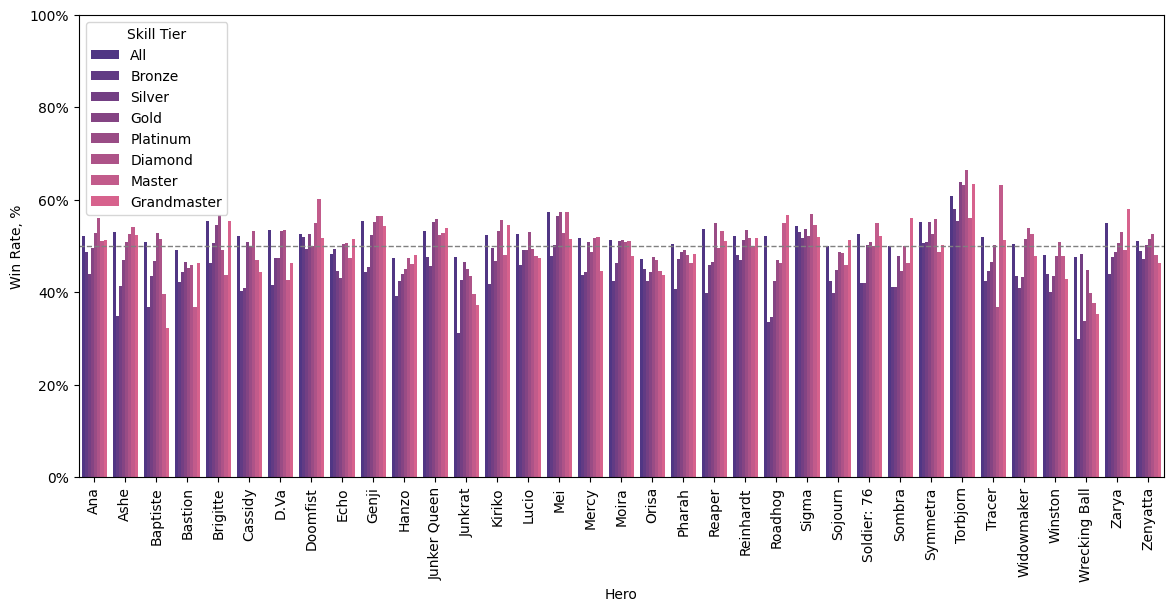

In [5]:
hero_order = sorted(set(df["Hero"]))
tier_order = ["All", "Bronze", "Silver", "Gold", "Platinum", "Diamond", "Master", "Grandmaster"]

palette = sns.blend_palette(["#4B2991", "#EA4F88"], n_colors=len(tier_order))

fig, ax = plt.subplots(figsize=(14, 6))

sns.barplot(data=df, x="Hero", y="Win Rate, %", hue="Skill Tier",
            hue_order=tier_order, order=hero_order, palette=palette, errorbar=None, ax=ax)

ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.axhline(50, color="grey", linestyle="--", linewidth=1)

plt.xticks(rotation=90)
plt.show()

Let's now load the season 2 data and merge both seasons on hero and rank.
We should also calculate the win rate difference between the 2 seasons (positive means an increase in season 2).

By precautions, we also check that no hero was lost in the merge.

In [6]:
df2 = pd.read_csv("/content/drive/MyDrive/Data Acquisition Exercises/Project/ow2_season_02_FINAL_heroes_stats.csv")

merged = df.merge(df2, on=["Hero", "Skill Tier"], suffixes=("_s1", "_s2"),
                  how="inner", validate="one_to_one")

merged["WR_diff"] = merged["Win Rate, %_s2"] - merged["Win Rate, %_s1"]

print(len(df), len(df2), len(merged))

280 288 280


As we can see, there is in fact a difference in length, an 8 points difference, which corresponds to the stats of one hero (7 ranks + 1 all).
But it is not an error: if we look closely, we can see which hero is missing from the season 1 dataset.

In [7]:
heroes_s1 = set(df["Hero"].unique())
heroes_s2 = set(df2["Hero"].unique())


print("Only in season 2:", sorted(heroes_s2 - heroes_s1))

Only in season 2: ['Ramattra']


The reason: the hero Ramattra came out in the game at the beginning of season 2, the 6th of december 2022, thus it can't be present in the season 1 dataset. So we will ignore it for this project.

Let's see now what differences in win rates there are between the season 1 and the season 2 for each heroes.
The objective here is to display the same graphic as the previous one (season 1) but with the difference in percentage added in green to the previous the corresponding season 1 value if the win rate increased and if the win rate decreased, we remove from the previous value in red.

So first, we determine a common hero order for both seasons so the bars line up.

Then we create the figure and make the middle layer, which are the season 1 gradient bars (zorder set at 2 as it will be the middle layer).

After a little setup for a cleaner result, we then add the season 2 layers, one rank at a time. For each rank, the loop goes through every hero in the merged table and compares the season 1 win rate with the season 2 win rate. It places the bar at the same horizontal position as the matching season 1 bar. If the win rate increased, it draws a green bar up to the season 2 value behind the season 1 bar, so only the extra part above it is visible. If the win rate decreased, it draws a red segment in front of the season 1 bar, from the season 2 value up to the season 1 value, which shows the part that was lost.

And finally, after a bit more cleanup and setting up the legend, we can display the plot.

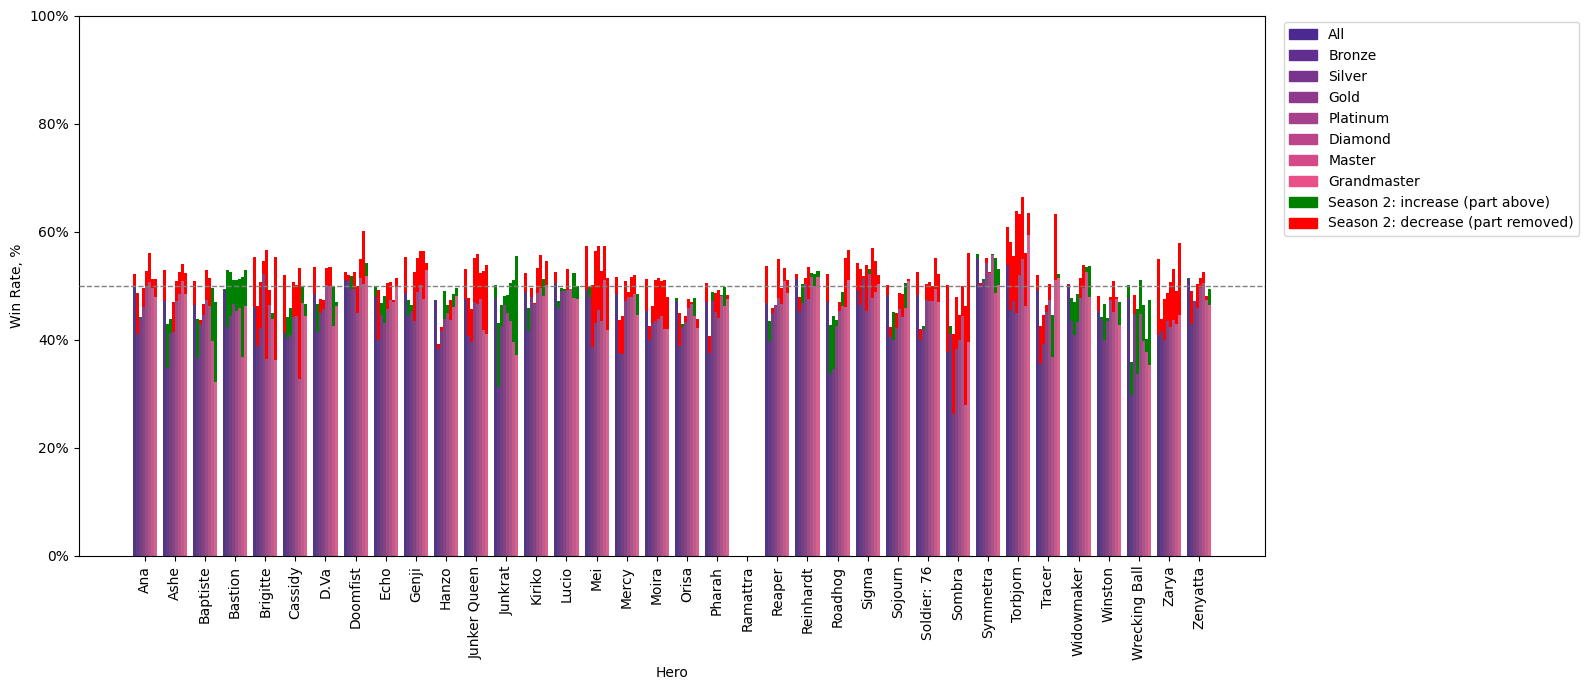

In [8]:
hero_order = sorted(set(df["Hero"]) | set(df2["Hero"]))

fig, ax = plt.subplots(figsize=(16, 7))
sns.barplot(data=df, x="Hero", y="Win Rate, %", hue="Skill Tier",
            order=hero_order, hue_order=tier_order, palette=palette,
            errorbar=None, ax=ax, zorder=2)

# Width of one bar inside a hero group (seaborn uses a group width of 0.8)
n_tiers = len(tier_order)
bar_width = 0.8 / n_tiers
# x position of each hero on the axis
hero_pos = {hero: i for i, hero in enumerate(hero_order)}

for t_idx, tier in enumerate(tier_order):
    # Horizontal shift of this rank inside a hero group (same layout as seaborn)
    shift = (t_idx - (n_tiers - 1) / 2) * bar_width

    # Rows of the merged table for this rank
    sub = merged[merged["Skill Tier"] == tier]

    # Go through the heroes one by one
    for _, row in sub.iterrows():
        # Centre of the bar = position of the hero + shift of the rank
        x = hero_pos[row["Hero"]] + shift

        # Win rates of the two seasons for this hero and this rank
        wr_s1 = row["Win Rate, %_s1"]
        wr_s2 = row["Win Rate, %_s2"]

        if wr_s2 >= wr_s1:
            # Increase: green bar at the season 2 height, drawn behind the season 1 bar
            ax.bar(x, wr_s2, width=bar_width, color="green", zorder=1)
        else:
            # Decrease: red segment from the season 2 value up to the season 1 value, drawn in front
            ax.bar(x, wr_s1 - wr_s2, bottom=wr_s2, width=bar_width, color="red", zorder=3)

# Full 0-100 scale with percent ticks
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

# 50 % reference line, drawn above the bars
ax.axhline(50, color="grey", linestyle="--", linewidth=1, zorder=4)

# Readable hero names
plt.xticks(rotation=90)

# Legend: one entry per rank plus the season 2 colours
handles = [Patch(color=c, label=t) for t, c in zip(tier_order, palette)]
handles += [Patch(color="green", label="Season 2: increase (part above)"),
            Patch(color="red", label="Season 2: decrease (part removed)")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.show()

As it may be a bit difficult to see the values, we can make a table out of the merging of the 2 dataset: One row per hero, one column per rank and values equal to the win rate difference. As we don't need a palette for the ranks anymore, we can use a gradient palette of red (for negative) to green (for positive)

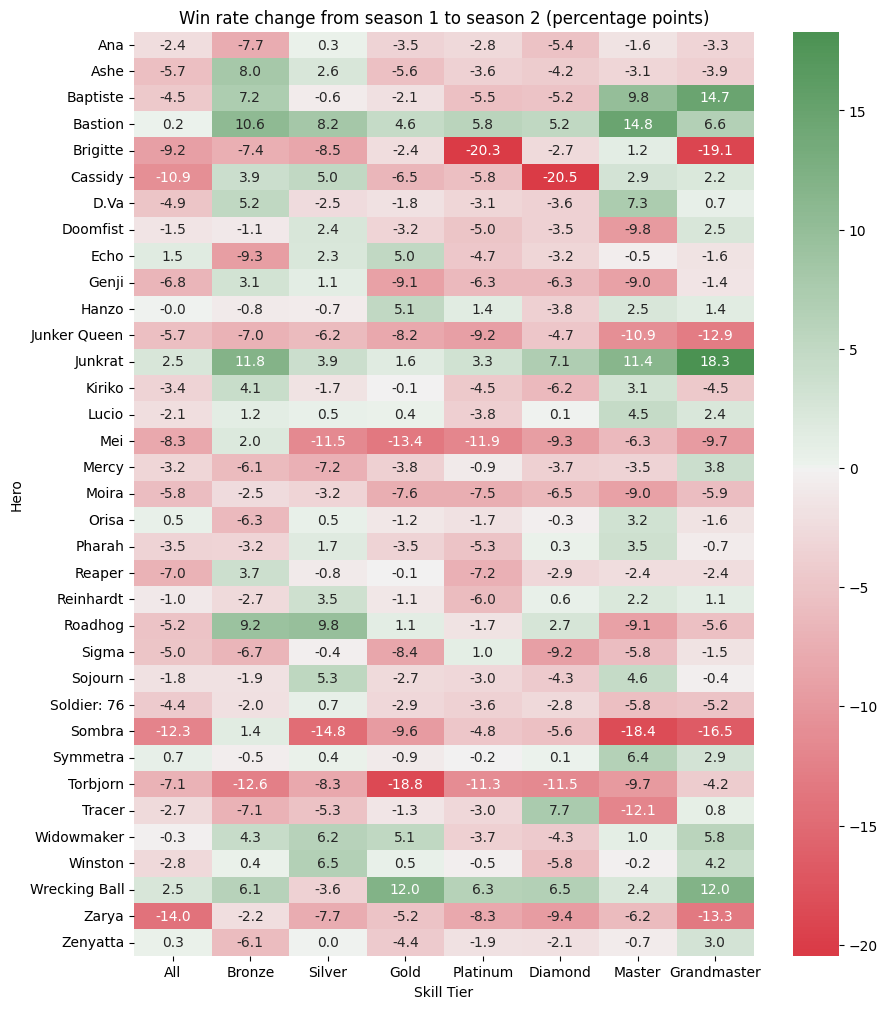

In [9]:
pivot = merged.pivot(index="Hero", columns="Skill Tier", values="WR_diff")[tier_order]

cmap = sns.diverging_palette(10, 130, as_cmap=True)

plt.figure(figsize=(10, 12))
sns.heatmap(pivot, cmap=cmap, center=0, annot=True, fmt=".1f")
plt.title("Win rate change from season 1 to season 2 (percentage points)")
plt.show()

Before continuing, by observing the data, I realized the All stat doesn't really make sense. If it was a simple mean of the values combined of all ranks, and even if we were to consider the pickrate, it wouldn't make any sense why a hero like Bastion, who gained between 5% and 15% for every single rank would only have a 0.2% win rate increase in All. No amount of pickrate or whatever could explain that either, or at the very least, it is highly likely not the case. So I suppose it must include other data like from unranked matches, but that is not very relevant for what we are trying to do with this project so we will ignore this stat from now on.

Well, now, let's begin the fun part.

# Reasons behind increasing and decreasing win rate

The reason is actually quite simple: the devs behind Overwatch made some patches between the season 1 and season 2. So by going on their official website, we will do a bit of web scraping to see what buffs/nerfs took place between the 6th of december 2022 (end of season 1 == season 1 dataset) and the 7th of february 2023 (end of season 2 == season 2 dataset).

Objective: make a list of number of buffs/nerfs per hero during this period of time and see if it correlates with their win rates.

The web pages that we will be using are :
- https://overwatch.blizzard.com/en-gb/news/patch-notes/live/2022/12/
- https://overwatch.blizzard.com/en-gb/news/patch-notes/live/2023/1/

(not february, because it would be irrelevant as the first patch of february happened the 7th, which is also the end of season 2 and the beginning of season 3, so it won't have any effect on the season 2's win rate stats).

In these pages, we will focus on the "Hero updates" parts (reminder: we will ignore Ramattra).

Let's make an algorithm that will automatically find and list every buffs and nerfs of each hero in the mentioned pages.
Here are some keywords that must be present in a change. These keywords will help the algorithm determine what's a buffs and what's a nerf:
- "cooldown" + "increased" == Nerf | "reduced" == Buff
- "damage falloff" + "increased" == Buff | "reduced" == Nerf (most base projectiles in the game have damage fallof at a specific range. Increasing that range means increasing the damage that would have otherwise been reduced before at a same range)
- "movement speed" + "increased" == Buff | "reduced" == Nerf
- "armor bonus" + "increased" == Buff | "reduced" == Nerf
- "damage" + "increased" == Buff | "reduced" == Nerf
- "healing" + "increased" == Buff | "reduced" == Nerf
- "spread" + "increased" == Nerf | "reduced" == Buff (for heroes using a weapon that fires multiple projectiles, they are more or less centered on the crossair depending on a given spread)
- "ammo" + "increased" == Buff | "reduced" == Nerf
- "reload time" + "increased" == Nerf | "reduced" == Buff
- "ultimate cost" + "increased" == Nerf | "reduced" == Buff
- Starts with "duration" + "increased" == Buff | "reduced" == Nerf
- "effect duration" + "increased" == Buff | "reduced" == Nerf
- "invulnerability duration" + "increased" == Buff | "reduced" == Nerf
- "stun duration" + "increased" == Buff | "reduced" == Nerf
- "knockback radius" + "increased" == Buff | "reduced" == Nerf
- "slow duration" + "increased" == Buff | "reduced" == Nerf
- "health" + "increased" == Buff | "reduced" == Nerf
- "wound duration" + "increased" == Buff | "reduced" == Nerf
- "charge rate" + "increased" == Buff | "reduced" == Nerf
- "decay rate" + "increased" == Nerf | "reduced" == Buff
- Starts with "energy degeneration" + "increased" == Buff | "reduced" == Nerf
- "minimum time before cancel option" + "increased" == Nerf | "reduced" == Buff
- "minimum" + "required" + "increased" == Nerf | "reduced" == Buff
- "delay" + "increased" == Nerf | "reduced" == Buff
- "cast time" + "increased" == Nerf | "reduced" == Buff
- "recovery time" + "increased" == Nerf | "reduced" == Buff
- "weapon swap time" + "increased" == Nerf | "reduced" == Buff
- "hit volume" + "increased" == Nerf | "reduced" == Buff
- "now" == Buff (new characteristics)
- "again" == Buff (reuse of a previous characteristic that was removed in a previous patch)
- "no longer" == Nerf (changes where something is removed) /!\\ exception: if also "damage to self" in the same change, then it is a buff
- if "no longer" and "now" in one change == 1 buff and 1 nerf

If no conditions or 2 (or more) conditions are validated for one change, the algorithm will return the change as an error. Errors won't stop the program. They simply won't count as Buffs nor Nerfs. Each changes that provoked an error will be displayed at the end (with the corresponding hero). We will then manually assign them as buff or nerf.

In [10]:
import re
import unicodedata
from datetime import date

import pandas as pd
import requests
from bs4 import BeautifulSoup

# ---------------------------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------------------------

# Monthly patch note pages to scrape
URLS = [
    "https://overwatch.blizzard.com/en-gb/news/patch-notes/live/2022/12/",
    "https://overwatch.blizzard.com/en-gb/news/patch-notes/live/2023/1/",
]

# Season 2 window: patches outside of it are skipped when a date can be found
SEASON_START = date(2022, 12, 6)
SEASON_END = date(2023, 2, 7)  # exclusive

# Heroes to ignore (lower case)
EXCLUDED_HEROES = {"ramattra"}

# False = strict rule (2+ matching conditions -> error); True = accept them if they all give the same result
ALLOW_SAME_RESULT = False

# Words giving the direction of a change
INCREASED = ("increased",)
REDUCED = ("reduced", "decreased")

# Each rule: (name, keywords that must ALL be present, must start the change, result if increased, result if reduced)
DIRECTIONAL_RULES = [
    ("cooldown", ("cooldown",), False, "nerf", "buff"),
    ("damage falloff", ("damage falloff",), False, "buff", "nerf"),
    ("movement speed", ("movement speed",), False, "buff", "nerf"),
    ("armor bonus", ("armor bonus",), False, "buff", "nerf"),
    ("damage", ("damage",), False, "buff", "nerf"),
    ("healing", ("healing",), False, "buff", "nerf"),
    ("spread", ("spread",), False, "nerf", "buff"),
    ("ammo", ("ammo",), False, "buff", "nerf"),
    ("reload time", ("reload time",), False, "nerf", "buff"),
    ("ultimate cost", ("ultimate cost",), False, "nerf", "buff"),
    ("duration (at start)", ("duration",), True, "buff", "nerf"),
    ("effect duration", ("effect duration",), False, "buff", "nerf"),
    ("invulnerability duration", ("invulnerability duration",), False, "buff", "nerf"),
    ("stun duration", ("stun duration",), False, "buff", "nerf"),
    ("knockback radius", ("knockback radius",), False, "buff", "nerf"),
    ("slow duration", ("slow duration",), False, "buff", "nerf"),
    ("health", ("health",), False, "buff", "nerf"),
    ("wound duration", ("wound duration",), False, "buff", "nerf"),
    ("charge rate", ("charge rate",), False, "buff", "nerf"),
    ("decay rate", ("decay rate",), False, "nerf", "buff"),
    ("energy degeneration (at start)", ("energy degeneration",), True, "buff", "nerf"),
    ("minimum time before cancel option", ("minimum time before cancel option",), False, "nerf", "buff"),
    ("minimum ... required", ("minimum", "required"), False, "nerf", "buff"),
    ("delay", ("delay",), False, "nerf", "buff"),
    ("cast time", ("cast time",), False, "nerf", "buff"),
    ("recovery time", ("recovery time",), False, "nerf", "buff"),
    ("weapon swap time", ("weapon swap time",), False, "nerf", "buff"),
    ("hit volume", ("hit volume",), False, "nerf", "buff"),
]

# ---------------------------------------------------------------------------
# 2. Classification of one change
# ---------------------------------------------------------------------------


def find_phrase(text, phrase):
    # Return (start, end) of the first whole-word occurrence of the phrase, or None
    m = re.search(r"\b" + re.escape(phrase) + r"\b", text)
    return (m.start(), m.end()) if m else None


def classify(text):
    # Return (label, matched rules, error reason); label is buff / nerf / buff+nerf / error
    t = re.sub(r"\s+", " ", text.lower()).strip()

    # Direction: exactly one of the two families of words must be present
    has_inc = any(find_phrase(t, w) for w in INCREASED)
    has_red = any(find_phrase(t, w) for w in REDUCED)
    if has_inc and not has_red:
        direction = "inc"
    elif has_red and not has_inc:
        direction = "red"
    else:
        direction = None

    # Directional rules: keyword(s) present AND a clear direction word
    candidates = []
    if direction:
        for name, keywords, at_start, if_inc, if_red in DIRECTIONAL_RULES:
            spans = [find_phrase(t, k) for k in keywords]
            if None in spans:
                continue
            start = min(s[0] for s in spans)
            end = max(s[1] for s in spans)
            if at_start and start != 0:
                continue
            candidates.append((start, end, name, if_inc if direction == "inc" else if_red))

    # A rule whose text lies inside a longer matched rule is dropped
    # (e.g. "damage" inside "damage falloff" or inside "minimum ... required")
    kept = []
    for c in candidates:
        inside = any(
            o is not c and o[0] <= c[0] and c[1] <= o[1] and (o[1] - o[0]) > (c[1] - c[0])
            for o in candidates
        )
        if not inside:
            kept.append(c)

    # Each condition is (rule name, list of results it produces)
    conditions = [(name, [result]) for _, _, name, result in kept]

    # Rules without a direction word
    has_now = find_phrase(t, "now")
    has_again = find_phrase(t, "again")
    has_no_longer = find_phrase(t, "no longer")
    if has_now and has_no_longer:
        conditions.append(("now + no longer", ["buff", "nerf"]))
    elif has_now:
        conditions.append(("now", ["buff"]))
    elif has_no_longer:
        # Exception: removing a "damage to self" effect is a buff
        conditions.append(("no longer", ["buff" if "damage to self" in t else "nerf"]))
    if has_again:
        conditions.append(("again", ["buff"]))

    # Decision: exactly one condition is required (unless same-result mode is on)
    if not conditions:
        return "error", "", "no condition matched"
    names = ", ".join(n for n, _ in conditions)
    if len(conditions) > 1:
        same = len({tuple(r) for _, r in conditions}) == 1
        if not (ALLOW_SAME_RESULT and same):
            return "error", names, "several conditions matched"
    return "+".join(sorted(conditions[0][1])), names, ""


# ---------------------------------------------------------------------------
# 3. Reading the HTML
# ---------------------------------------------------------------------------

MONTHS = ["january", "february", "march", "april", "may", "june", "july",
          "august", "september", "october", "november", "december"]
MONTH_RE = "|".join(MONTHS)

# Matches "6 December 2022" and "December 6, 2022"
DATE_RE = re.compile(
    r"\b(\d{1,2})(?:st|nd|rd|th)?\s+(" + MONTH_RE + r")\s+(\d{4})\b"
    r"|\b(" + MONTH_RE + r")\s+(\d{1,2})(?:st|nd|rd|th)?,?\s+(\d{4})\b",
    re.IGNORECASE,
)


def parse_date(text):
    # Return the first date found in the text, or None
    m = DATE_RE.search(text)
    if not m:
        return None
    if m.group(1):
        day, month, year = int(m.group(1)), m.group(2), int(m.group(3))
    else:
        month, day, year = m.group(4), int(m.group(5)), int(m.group(6))
    return date(year, MONTHS.index(month.lower()) + 1, day)


def find_patch_date(block):
    # Nearest date written before this hero block in the page (patch title), or None
    for s in block.find_all_previous(string=True):
        d = parse_date(s)
        if d:
            return d
    return None


def normalize_hero(name):
    # Remove accents so "Lúcio" / "Torbjörn" match the Kaggle names
    n = unicodedata.normalize("NFKD", name)
    return "".join(c for c in n if not unicodedata.combining(c)).strip()


def parse_page(html, source=""):
    # Return one row per change found in the "hero updates" blocks of a page
    soup = BeautifulSoup(html, "html.parser")
    rows = []

    for block in soup.select("div.PatchNotesHeroUpdate"):
        hero = normalize_hero(block.select_one(".PatchNotesHeroUpdate-name").get_text(strip=True))
        if hero.lower() in EXCLUDED_HEROES:
            continue

        # Skip patches outside the season window (when the date is known)
        patch_date = find_patch_date(block)
        if patch_date and not (SEASON_START <= patch_date < SEASON_END):
            continue

        # Role title (TANK / DAMAGE / SUPPORT) and developer comments, kept for manual review
        role_tag = block.find_previous("h4", class_="PatchNotes-sectionTitle")
        role = role_tag.get_text(strip=True) if role_tag else ""
        dev_tag = block.select_one(".PatchNotesHeroUpdate-dev")
        dev_comment = dev_tag.get_text(" ", strip=True) if dev_tag else ""

        # General changes first, then ability by ability
        entries = [("General", li.get_text(" ", strip=True))
                   for li in block.select(".PatchNotesHeroUpdate-generalUpdates li")]
        for ability in block.select(".PatchNotesAbilityUpdate"):
            ab_name = ability.select_one(".PatchNotesAbilityUpdate-name").get_text(strip=True)
            entries += [(ab_name, li.get_text(" ", strip=True))
                        for li in ability.select(".PatchNotesAbilityUpdate-detailList li")]

        for ability_name, text in entries:
            label, rules, reason = classify(text)
            rows.append({
                "Hero": hero, "Role": role, "Patch date": patch_date, "Ability": ability_name,
                "Change": text, "Label": label, "Rules": rules, "Error reason": reason,
                "Dev comment": dev_comment, "Source": source,
            })

    return pd.DataFrame(rows)


def fetch(url):
    # Download a page; a browser-like user agent avoids some blocks
    r = requests.get(url, headers={"User-Agent": "Mozilla/5.0 (student data project)"}, timeout=30)
    r.raise_for_status()
    return r.text


# ---------------------------------------------------------------------------
# 4. Summary per hero
# ---------------------------------------------------------------------------


def summarize(changes, overrides=None):
    # overrides: {(hero, change text): "buff" | "nerf" | "buff+nerf" | "ignore"} for the errors
    c = changes.copy()
    for (hero, text), label in (overrides or {}).items():
        c.loc[(c["Hero"] == hero) & (c["Change"] == text) & (c["Label"] == "error"), "Label"] = label

    c["buffs"] = c["Label"].isin(["buff", "buff+nerf"]).astype(int)
    c["nerfs"] = c["Label"].isin(["nerf", "buff+nerf"]).astype(int)
    c["errors"] = (c["Label"] == "error").astype(int)

    out = c.groupby("Hero")[["buffs", "nerfs", "errors"]].sum().reset_index()
    out["net"] = out["buffs"] - out["nerfs"]
    return out


def print_errors(changes):
    # Display every change that could not be classified, with its hero
    errors = changes[changes["Label"] == "error"]
    print(len(errors), "changes to label manually:\n")
    for _, r in errors.iterrows():
        print(f"- {r['Hero']} | {r['Ability']} | {r['Change']}  [{r['Error reason']}: {r['Rules']}]")


# Download and parse both monthly pages
all_changes = pd.concat([parse_page(fetch(u), u) for u in URLS], ignore_index=True)

# Summary per hero, then the changes that need a manual label
summary = summarize(all_changes)
print_errors(all_changes)

8 changes to label manually:

- Ana | Biotic Rifle | Damage and Healing increased from 70 to 75  [several conditions matched: damage, healing]
- Doomfist | Rocket Punch | This has been in since his rework but was not mentioned  [no condition matched: ]
- Junker Queen | Adrenaline Rush | Adrenaline passive healing multiplier increased from 1 to 1.25x damage dealt by wounds  [several conditions matched: damage, healing]
- Symmetra | Proton Projector | Beam charge rate and decay rate increased by 20%  [several conditions matched: charge rate, decay rate]
- Kiriko | General | Arm hit volumes width reduced 15%  [no condition matched: ]
- Kiriko | General | Added an auto-wall climb hero option  [no condition matched: ]
- Roadhog | Chain Hook | The enemy final position distance from Roadhog after being pulled increased from 3 to 4 meters  [no condition matched: ]
- Junker Queen | Carnage | Cooldown is now reduced by 2 seconds for each enemy it impacts  [several conditions matched: cooldown, n

So let's label those 8 changes that were returned.

For Ana, we can consider it to be a single buff, even if damage and healing were increased. Because the skill simply deals damage or heals depending on if it's an enemy or an ally. So it can be considered as one.

For Doomfist, the line refers to the changes not being mentioned for his "rocket punch". We will still keep the buffs and nerfs assossiated with the skill none the less. Neither a buff nor a nerf.

For Junker Queen, it's a buff. Junker Queen can basically heal herself if she deals damage to enemies (by applying a "wound" debuff). So increasing the multiplayer is good.

For Symmetra, it refers to her primary fire, which a laser that deals progressively more damage the more she deals damage to an enemy. So increasing the charge rate (the speed at which the damage increases) is a buff, and increasing the decay rate (the speed at which she loses the damage amplification when not dealing damage) is a nerf.

For Kiriko, the arm hit volumes being reduced is a buff, meaning her hitbox is smaller. For the addition of auto wall climb, it's not really a buff, just a new option that may or may not be beneficial to players (and which can be deactivated).

For Roadhog, it's a buff. This hero uses a shotgun, making it more effective at close range. The chain hook is a skill that can grab enemies and bring them closer to the hero. And by being closer, they are more likely to take more damage from the shotgun.

And the last one, for Junker Queen again, it's a buff.

Let's now add all that to the list of buffs and nerfs.

In [11]:
# Manual labels for the 8 changes the algorithm could not classify
# Key = (hero, exact text of the change); value = "buff", "nerf", "buff+nerf" or "ignore"
overrides = {
    ("Ana", "Damage and Healing increased from 70 to 75"): "buff",
    ("Doomfist", "This has been in since his rework but was not mentioned"): "ignore",
    ("Junker Queen", "Adrenaline passive healing multiplier increased from 1 to 1.25x damage dealt by wounds"): "buff",
    ("Symmetra", "Beam charge rate and decay rate increased by 20%"): "buff+nerf",
    ("Kiriko", "Arm hit volumes width reduced 15%"): "buff",
    ("Kiriko", "Added an auto-wall climb hero option"): "ignore",
    ("Roadhog", "The enemy final position distance from Roadhog after being pulled increased from 3 to 4 meters"): "buff",
    ("Junker Queen", "Cooldown is now reduced by 2 seconds for each enemy it impacts"): "buff",
}

# Apply the labels and build the final table
summary = summarize(all_changes, overrides)

# Check that no error is left (the "errors" column should be 0 everywhere)
print(summary["errors"].sum())
print(summary)

0
            Hero  buffs  nerfs  errors  net
0            Ana      3      0       0    3
1        Bastion      4      1       0    3
2       Brigitte      1      0       0    1
3       Doomfist     11      6       0    5
4   Junker Queen      6      3       0    3
5         Kiriko      5      4       0    1
6          Mercy      2      0       0    2
7          Moira      1      0       0    1
8          Orisa      2      1       0    1
9        Roadhog      4      2       0    2
10       Sojourn      4      5       0   -1
11      Symmetra      3      1       0    2
12        Tracer      1      1       0    0
13         Zarya      0      2       0   -2


Now then, let's compare with the win rate difference for each heroes who received buffs or nerfs.

## Ana
Now this one is interesting because even while she received buffs, her win rate accross almost all ranks went down between the 2 season. But maybe that in itself explains why she received buffs. The devs, seeing as she was starting to lose more decided to give her buffs, which maybe weren't good enough to compensate. An other reason might be in the increased win rate of heroes like Wrecking ball. Ana is a hero that has absolutely no skills that allow her to move around. Being a support, she also doesn't have a lot of hp. Heroes like wrecking ball, who is a tank "dive" (that specilizes in attacking the back line) with a lot of hp, that moves quickly, and does damage while moving might be a reason why she loses more too. This kind of situation is what defines the META in video games. Sometimes, it can be obvious when some heroes are too strong or too weak, but sometimes, it can also be a simple shift in playstyle.

## Bastion
This one is obvious. He received buffs, the only nerf he got was based on his ultimate, which isn't his best skill anyway, so it makes sense that his win rate went up accross all ranks.

## Brigitte
Brigitte is in a similar situation to Ana. The buff she received is probably because she was starting to lose too much so the devs decided to give her a buff in health in the hope she wouldn't fall too far off. After all, she received a buff mid season in january, which reinforces the idea of the devs trying to give her a bit more impact. Comparing the data with the 3rd season could help on this one.

## Doomfist
Doomfist received a lot of buffs and nerfs at the same time. For his win rates, some ranks gained win rate, other lost. Globally, we can see that he lost more win rate overall. This is a good example of buffs and nerfs impact. In fact, if we look back again on the website, http://overwatch.blizzard.com/en-gb/news/patch-notes/live/2022/12, first of all, for the patch note at the beginning of the season (6th of december), it is mentionned that "This has been in since his rework but was not mentioned" meaning some of the buffs we enlisted were already active. Second, we can see an interesting pattern: on the second patch of the season, 15th of december, we can see that Doomfist received massive nerfs: cooldown increase on his main skill (rocket punch, his main source of damage), his blocking skill (power block), who is supposed to block damage and empower his rocket punch (increase its range and damge) needs to mitigate more damage than before for it to empower the rocket punch, and finally his passive, which grants over health by dealing damage, the amount of overhealth gained was reduced too, making the hero deals less damage, and be less capable of tanking the damage. That is a typical situation in competitive video games to be honest: a hero is buffed too much at the begining, so the devs have to nerf him a lot soon after, often too harshly, which impacts his win rate for the rest of the season. Tho the win rate didn't seem to move that much compared to other heroes, some ranks gained in win rate for this hero, other lost, so we could conclude that the balancing was kinda successful.

## Junker Queen
Junker Queen's win rate went down quite a lot accross all ranks. Yet she received quite a lot of buffs. By looking more in details at the patch note, we can see that one nerf she got was the increase of her volume, or hitbox, making her more susceptible to taking damage (she also is a tank who's played at the front line, so it doesn't help, plus the head hit box increased, which is really bad because in Overwatch, shooting at the head of a hero deals critical damage (generally 1.5x the damage she would have taken elsewhere)). Most of her buffs increases the amount of heal she receives via her passive, so it only tries to compensate for the hitbox increase. She also received a buff on one of her cooldown by 1 second but for an ability that had originally a 15 seconds cooldown, so it doesn't do much, and her ultimate costs 10% less, but that isn't that good either, considering her ultimate can quite easily be canceled by a lot of characters in the game. So, along with the changes in the meta, that may explains why her win rate decreased.

## Kiriko
Her overall win rate went down while having more buffs than nerfs. But for this one, it can be simply explained. The reason why Kiriko is a good is a good character that is played a lot is because of 2 abilities: her ultimate and a skill called protection suzu. And it so happens that she was nerfed on these specific abilities, while her buffs went to other parts of her kit that are definitely not as relevant. The devs tried to make her kit more balanced, thus nerfing the very reason of why she was very good, so it makes total sense why her win rate would go down.

## Mercy
Nothing to say for this one. Her buffs are not really impactful, so the overall decrease of win rate is probably caused by the meta.

## Moira
Her overall win rate went down, but like mercy, it's probably due to the meta shifting rather than a real balancing issue.

## Orisa
Decent buffs, and a nerf with a visible impact, it made her win rate go down in some ranks, and go up in other, so the balance was maintained.

## Roadhog
Buffs and nerfs, making him overall balanced, just like his win rate shows: went up in lower ranks, down in higher ranks. No specific correlation, probably more due to the meta shifting.

## Sojourn
Buffs, nerfs, and changes in her kit, making her overall balanced. Her win rate went up in some ranks, down in others.

## Symmetra
Good buffs, making her more impactful (the buffs made her deals more damage over a shorter period of time, making her more relevant as a dps unit), and it shows in her win rate as it overall went up.

## Tracer
The devs first buffed then nerfed her primary source of damage, which might explain her overall decrease of win rate, along the shifting of the meta.

## Zarya
Like Bastion, but the other way around. Two nerfs impacting her damage. It so makes sense why her win rate went down accross all ranks.

# Merging

So, until now, we've been using 2 separate ways to compare the data. So let's see how to put all the data in one table.

The following code first keeps the 7 individual ranks and drops “All” (because like said previously, it's not very clear therefore not useful here). It then checks that every hero of the scraped table exists in the Kaggle data. Next, it merges the buffs/nerfs table into the win rate table on the hero name, with a left merge: heroes with no change in the patch notes are kept and get 0 buffs and 0 nerfs. Each hero is then given a category (more buffs, more nerfs, equal, no change). Finally, since the 7 rows of a hero are not independent, it builds one row per hero containing the mean win rate difference over the 7 ranks.

In [12]:
# Individual ranks only: "All" is ignored, as explained above
tiers_only = [t for t in tier_order if t != "All"]

# Check that every hero of the scraped table exists in the Kaggle data (spelling must match)
print("Heroes not found in the Kaggle data:", set(summary["Hero"]) - set(merged["Hero"]))

# Keep the individual ranks only
data = merged[merged["Skill Tier"].isin(tiers_only)]

# Left merge: every hero/rank row is kept, even if the hero has no change in the patch notes
final = data.merge(summary[["Hero", "buffs", "nerfs", "net"]],
                   on="Hero", how="left", validate="many_to_one")

# Heroes without any change have no row in the summary: they get 0 instead of NaN
final[["buffs", "nerfs", "net"]] = final[["buffs", "nerfs", "net"]].fillna(0).astype(int)

# The merge must neither add nor remove rows
print(len(data), len(final))

# Category of each hero according to the balance of its changes
final["Category"] = np.select(
    [final["buffs"] + final["nerfs"] == 0, final["net"] > 0, final["net"] < 0],
    ["No change", "More buffs", "More nerfs"],
    default="Equal buffs and nerfs")

# One row per hero: mean win rate difference over the 7 ranks (the 7 rows of a hero are not independent)
hero_level = final.groupby("Hero").agg(
    WR_diff=("WR_diff", "mean"),
    WR_s1=("Win Rate, %_s1", "mean"),
    buffs=("buffs", "first"),
    nerfs=("nerfs", "first"),
    net=("net", "first"),
    Category=("Category", "first"),
).reset_index()

# Number of heroes per category
print(hero_level["Category"].value_counts())

Heroes not found in the Kaggle data: set()
245 245
Category
No change                21
More buffs               11
More nerfs                2
Equal buffs and nerfs     1
Name: count, dtype: int64


Not every hero got changes. But none the less, let's see if we can answer the initial question: do the heroes that received more buffs gained more win rate over the season ? Do the nerfed ones lose more win rate overall ?

We will try to answer that question by making a boxplot that compares the distribution of the win rate change in each category.
Each box shows the median and the spread of the heroes of a category, and each black dot is one hero. The dashed line marks 0, meaning no change in win rate.

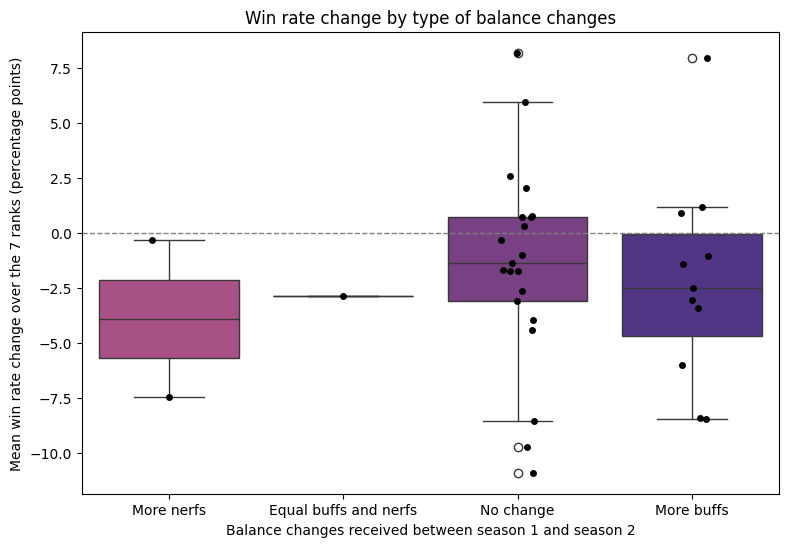

In [13]:
# Order of the categories, from the most nerfed to the most buffed
cat_order = ["More nerfs", "Equal buffs and nerfs", "No change", "More buffs"]

# Same purple-to-pink gradient as the rank palette, one colour per category
cat_palette = sns.blend_palette(["#4B2991", "#EA4F88"], n_colors=len(cat_order))

fig, ax = plt.subplots(figsize=(9, 6))

# One box per category
sns.boxplot(data=hero_level, x="Category", y="WR_diff", order=cat_order,
            hue="Category", palette=cat_palette, legend=False, ax=ax)

# Each dot is one hero
sns.stripplot(data=hero_level, x="Category", y="WR_diff", order=cat_order,
              color="black", size=5, ax=ax)

# Reference line: no change in win rate
ax.axhline(0, color="grey", linestyle="--", linewidth=1)

ax.set_xlabel("Balance changes received between season 1 and season 2")
ax.set_ylabel("Mean win rate change over the 7 ranks (percentage points)")
ax.set_title("Win rate change by type of balance changes")
plt.show()

The expected pattern (nerfed heroes at the bottom, buffed heroes at the top) does not appear. The median of the heroes with more buffs (about -2.5 points) is even lower than the median of the heroes with no change (about -1.4). The boxes of the nerfed and equal categories contain only 2 and 1 heroes, so they cannot be interpreted. The heroes with no change vary from about -11 to +8 points, which is as wide as the buffed heroes, so the win rate moves a lot even without a patch on the hero itself.
That pattern is interesting because it shows that buffs and nerfs are not made for no reason but as reactive measures installed by the devs while the meta is evolving, thus making it difficult to see a real pattern.

Let's now make a scatter plot that will help us answer a more detailed question: does a higher net balance (buffs minus nerfs) go with a bigger win rate gain, hero by hero?

In this scatterplot, each dot is a hero, coloured by category, with the name written for the heroes that received a change. The grey line is the linear trend over all heroes, and the grey area around it shows the uncertainty of that trend.

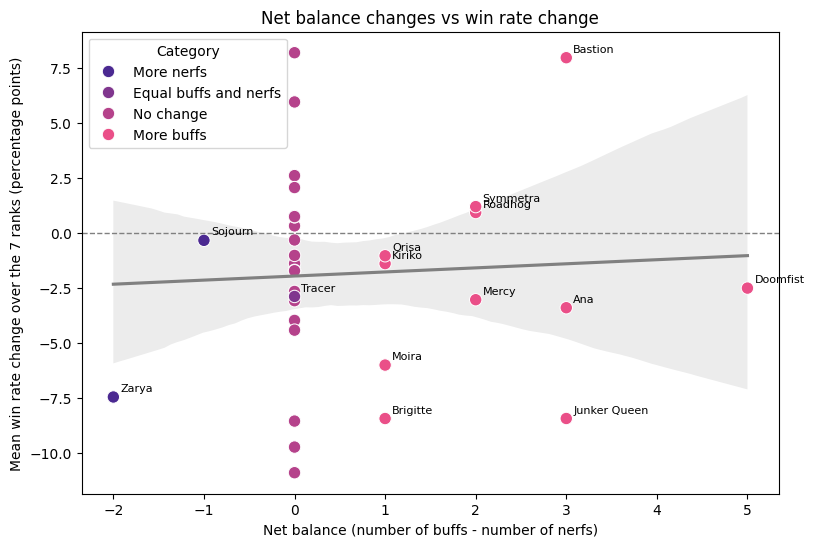

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))

# Trend line over all heroes
sns.regplot(data=hero_level, x="net", y="WR_diff", scatter=False, color="grey", ax=ax)

# One dot per hero, coloured by category
sns.scatterplot(data=hero_level, x="net", y="WR_diff", hue="Category",
                hue_order=cat_order, palette=cat_palette, s=80, ax=ax)

# Write the name of the heroes that received at least one change
for _, r in hero_level[hero_level["buffs"] + hero_level["nerfs"] > 0].iterrows():
    ax.annotate(r["Hero"], (r["net"], r["WR_diff"]), textcoords="offset points",
                xytext=(5, 4), fontsize=8)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Net balance (number of buffs - number of nerfs)")
ax.set_ylabel("Mean win rate change over the 7 ranks (percentage points)")
ax.set_title("Net balance changes vs win rate change")
plt.show()

As we can see, the trend line is almost flat and the uncertainty area is wide and contains 0, so we cannot say that the win rate increases with the net balance. Like we could see before, heroes with more buffs did not necesseraly gain more win rate. For the same amount of net balance (overall buffs - nerfs accross the season), we can see for example that Bastion is at +8 while Junker Queen is at -7.5 ish. Another thing that is very interesting is the unchanged heroes at 0 span almost the whole vertical range, which suggests that other factors, like the meta, weigh more than the changes counted here.

# Conclusion

More seasons might reveal a modest effect that 35 heroes cannot detect, but this data (this type of data to be more precise) does not allow us to say so.

The results seem to have no pattern aside from the fact that it tends to have a balanced heroes, which means that all heroes, accross the season, will tend to have a similar win rate. That is the problem with this thing called meta because we lack data that isn't really findable. That is why there a lot of "experts" of the game that sometimes dedicate their entire career trying to read this meta: which hero is currently the best (tier lists) ? for a specific hero, what other heroes counter him ? Because a counter to that specific hero is buffed or nerfed, it could probably explain a lot more why the win rate and pick rate of this specific hero changes. But how do we really know which hero has an advantage against another ? It depends on the rank at a given moment (because the meta can be different in each rank) and makes it difficult to determine a correlation, and it also depends on each individual player.

As there is no objective point of vue, no rule that dictates the win rate, from unbalanced heroes which make buffs and nerfs have a really obvious consequence on their win rate (like zarya and bastion) to other heroes whose win rate changes went the other way around, more buffs yet a loss in win rate (like doom fist or junker queen). We would need to compensate those lacking domains by an absurd amount of data, which we do not have access to.


# Post Scriptum
We could argue that this conclusion is not a good conclusion as it failed to answer the original question "is there a link between the win rate and the changes given to a hero". It should be answered by yes or no yet we couldn't affirm neither. But I personally think that it is a good example as to why data is so important nowadays. In the case of overwatch, in an ideal world, where we could get the detailed information of every single game, the habits of the players, even what they were thinking when they were playing or what made them want to play a specific hero more, we could define rules and patterns more easily, which could be a starting point for making something that could automatically balance heroes, without having the devs trying themselves to figure out what the meta is, which hero really needs buffs or nerfs and how much impact does it need for them to be balanced. And this active chase of trying to get the most data out of everything is one of the main objective of every enterprise right now.

In the end, the answer is that no link could be shown with this data, which is not the same as showing there is no link, just that we lack the data to prove it.